# Formative 2 – Part 1: Tabular Data & Product Recommendation Model
**Owner:** Member 1 (Amazing) &nbsp;|&nbsp; **Notebook:** `notebooks/01_tabular.ipynb`

**Goal.** Merge `customer_social_profiles` and `customer_transactions`, explore the data, engineer features
and train a model that predicts **which product category a customer buys**. The final function
`predict_product(customer_id)` (in `scripts/product_model.py`) is used by the command-line app after the
face check passes.

**Steps:** 1 Setup → 2 Load → 3 Inspect → 4 Clean & merge → 5 EDA → 6 Features → 7 Train → 8 Evaluate → 9 Save → 10 Test the function.

Random seed **42** is used everywhere.

## 1. Imports and setup

In [1]:
import os, sys, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, log_loss,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# Find the repository root whether the notebook is run from the root or from notebooks/
ROOT = os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else ".")
sys.path.insert(0, os.path.join(ROOT, "scripts"))
import product_model as pm      # our shared helper functions (cleaning + feature engineering)
print("Repository root:", ROOT)

Repository root: D:\ALU_Trials\dataPreProcessing


## 2. Load the datasets

In [2]:
profiles_raw = pd.read_csv(os.path.join(ROOT, "data", "raw", "customer_social_profiles.csv"))
trans_raw = pd.read_csv(os.path.join(ROOT, "data", "raw", "customer_transactions.csv"))
print("social profiles :", profiles_raw.shape)
print("transactions    :", trans_raw.shape)
profiles_raw.head()

social profiles : (155, 5)
transactions    : (150, 6)


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


In [3]:
trans_raw.head()

,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


## 3. Inspect the data (types, missing values, duplicates, ID format)

In [4]:
for name, df in [("customer_social_profiles", profiles_raw), ("customer_transactions", trans_raw)]:
    print("=" * 60, "\n", name, df.shape)
    print(df.dtypes.to_string())
    print("\nMissing values:\n", df.isna().sum().to_string())
    print("\nExact duplicate rows:", df.duplicated().sum())

 customer_social_profiles (155, 5)
customer_id_new                str
social_media_platform          str
engagement_score             int64
purchase_interest_score    float64
review_sentiment               str

Missing values:
 customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0

Exact duplicate rows: 5
 customer_transactions (150, 6)
customer_id_legacy      int64
transaction_id          int64
purchase_amount         int64
purchase_date             str
product_category          str
customer_rating       float64

Missing values:
 customer_id_legacy     0
transaction_id         0
purchase_amount        0
purchase_date          0
product_category       0
customer_rating       10

Exact duplicate rows: 0


In [5]:
# The two files name the customer ID differently AND store it in different formats
print("Profiles     :", profiles_raw["customer_id_new"].head(3).tolist(), "-> text with an 'A' prefix")
print("Transactions :", trans_raw["customer_id_legacy"].head(3).tolist(), "-> plain integers")
print("\nDuplicate rows in the profiles file:")
profiles_raw[profiles_raw.duplicated(keep=False)].sort_values("customer_id_new")

Profiles     : ['A178', 'A190', 'A150'] -> text with an 'A' prefix
Transactions : [151, 192, 114] -> plain integers

Duplicate rows in the profiles file:


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
18,A116,Twitter,78,1.1,Negative
151,A116,Twitter,78,1.1,Negative
73,A125,LinkedIn,66,4.7,Positive
150,A125,LinkedIn,66,4.7,Positive
76,A155,TikTok,98,4.8,Positive
154,A155,TikTok,98,4.8,Positive
78,A162,Twitter,71,4.8,Positive
153,A162,Twitter,71,4.8,Positive
118,A189,Twitter,59,3.8,Neutral
152,A189,Twitter,59,3.8,Neutral


**What we found**

| Issue | Where | Decision |
|---|---|---|
| ID names/formats differ (`customer_id_new` = `'A178'`, `customer_id_legacy` = `178`) | both files | Strip the `A` prefix and convert to integer; call the column `customer_id` in both |
| 5 exact duplicate rows | profiles | Drop them (they are copies, not new information) |
| 10 missing `customer_rating` values | transactions | Keep as missing; fill with the **median inside the model pipeline** so the fill value comes from training data only |
| A customer can have several profile rows (up to 7) | profiles | These are different platforms/snapshots, not errors. Summarise them to **one row per customer** (averages, shares, main platform) |
| A customer can have several transactions (up to 6) | transactions | Each transaction is kept as its own row – this is what we predict |

## 4. Clean and merge

In [6]:
profiles = pm.clean_profiles(profiles_raw)
trans = pm.clean_transactions(trans_raw)
print("profiles after cleaning:", profiles.shape, "(removed", len(profiles_raw) - len(profiles), "duplicate rows)")
print("transactions after cleaning:", trans.shape)
print("purchase_date dtype:", trans["purchase_date"].dtype)

profiles after cleaning: (150, 6) (removed 5 duplicate rows)
transactions after cleaning: (150, 6)
purchase_date dtype: datetime64[us]


### Join logic
* **Key:** `customer_id` (same integer format in both files after cleaning).
* **Join type: inner join.** A row is only useful for training if we know *both* the customer's social profile
  *and* their purchase. A left join would keep customers with no profile, and we would have to invent
  their social features. An inner join keeps only real data.
* **Relationship:** many transactions → one customer-level profile summary (`validate="m:1"` makes pandas
  raise an error if the profile side had duplicate IDs).

In [7]:
cust_profile = pm.build_customer_profile(profiles)          # one row per customer
merged_check = trans.merge(cust_profile, on="customer_id", how="inner", validate="m:1")

ids_t, ids_p = set(trans["customer_id"]), set(profiles["customer_id"])
print("---- Merge validation ----")
print("Transactions before merge          :", len(trans))
print("Rows after inner join              :", len(merged_check))
print("Customers in transactions          :", len(ids_t))
print("Customers in profiles              :", len(ids_p))
print("Customers in BOTH (kept)           :", len(ids_t & ids_p))
print("Transaction customers w/o profile  :", len(ids_t - ids_p), "(dropped)")
print("Profile customers w/o transactions :", len(ids_p - ids_t), "(dropped)")
print("Transactions lost by the join      :", len(trans) - len(merged_check))
print("Duplicate customer_id in profile summary:", cust_profile["customer_id"].duplicated().sum())
print("Duplicate transaction_id after merge     :", merged_check["transaction_id"].duplicated().sum())
print("Nulls introduced by the join             :", merged_check[cust_profile.columns].isna().sum().sum())

---- Merge validation ----
Transactions before merge          : 150
Rows after inner join              : 117
Customers in transactions          : 75
Customers in profiles              : 84
Customers in BOTH (kept)           : 61
Transaction customers w/o profile  : 14 (dropped)
Profile customers w/o transactions : 23 (dropped)
Transactions lost by the join      : 33
Duplicate customer_id in profile summary: 0
Duplicate transaction_id after merge     : 0
Nulls introduced by the join             : 0


**Reading the checks.** The join keeps the customers found in both files and drops the rest, with no duplicated
keys and no nulls introduced. Dropped customers are listed in the counts above. Because the dataset is small, this loss matters
and is mentioned again in the limitations.

## 5. Exploratory Data Analysis (EDA)

In [8]:
print("Merged shape:", merged_check.shape)
print("\nVariable types:\n", merged_check.dtypes.to_string())
print("\nSummary statistics (numeric):")
merged_check.describe().T.round(2)

Merged shape: (117, 13)

Variable types:
 customer_id                       int64
transaction_id                    int64
purchase_amount                   int64
purchase_date            datetime64[us]
product_category                    str
customer_rating                 float64
n_profiles                        int64
avg_engagement                  float64
avg_purchase_interest           float64
share_positive                  float64
share_neutral                   float64
share_negative                  float64
main_platform                       str

Summary statistics (numeric):


,count,mean,min,25%,50%,75%,max,std
customer_id,117.0,147.91453,100.0,117.0,146.0,180.0,199.0,32.288722
transaction_id,117.0,1074.25641,1001.0,1036.0,1073.0,1113.0,1150.0,44.27328
purchase_amount,117.0,287.905983,62.0,183.0,280.0,397.0,495.0,120.084165
purchase_date,117,2024-03-14 06:09:13.846153,2024-01-01 00:00:00,2024-02-05 00:00:00,2024-03-13 00:00:00,2024-04-22 00:00:00,2024-05-29 00:00:00,NaN
customer_rating,109.0,3.116514,1.0,2.1,3.3,4.2,5.0,1.23884
n_profiles,117.0,1.820513,1.0,1.0,2.0,2.0,4.0,0.896501
avg_engagement,117.0,74.154558,50.0,66.5,77.0,83.0,99.0,12.67478
avg_purchase_interest,117.0,3.077208,1.0,2.666667,3.133333,3.7,4.8,1.039644
share_positive,117.0,0.405271,0.0,0.0,0.333333,1.0,1.0,0.438905
share_neutral,117.0,0.293447,0.0,0.0,0.0,0.5,1.0,0.374856


In [9]:
print("Missing values after merge:\n", merged_check.isna().sum()[lambda s: s > 0].to_string())
print("\nSummary statistics (categorical):")
merged_check[["product_category", "main_platform"]].describe()

Missing values after merge:
 customer_rating    8

Summary statistics (categorical):


,product_category,main_platform
count,117,117
unique,5,5
top,Sports,Facebook
freq,28,32


### Plot 1 – Distribution of the target (product category) and of purchase amount

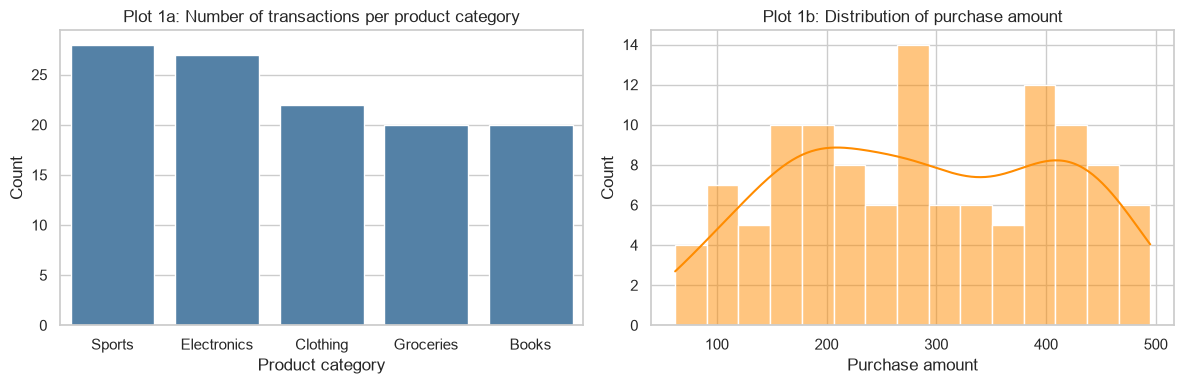

product_category
Sports         0.239
Electronics    0.231
Clothing       0.188
Groceries      0.171
Books          0.171


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
order = merged_check["product_category"].value_counts().index
sns.countplot(data=merged_check, x="product_category", order=order, color="steelblue", ax=ax[0])
ax[0].set_title("Plot 1a: Number of transactions per product category")
ax[0].set_xlabel("Product category"); ax[0].set_ylabel("Count")
sns.histplot(merged_check["purchase_amount"], bins=15, kde=True, color="darkorange", ax=ax[1])
ax[1].set_title("Plot 1b: Distribution of purchase amount")
ax[1].set_xlabel("Purchase amount"); ax[1].set_ylabel("Count")
plt.tight_layout(); plt.show()
print(merged_check["product_category"].value_counts(normalize=True).round(3).to_string())

**Interpretation.** The five categories are fairly balanced (largest ≈ 24 %, smallest ≈ 17 %), so a model that always
guesses the biggest class would only be right about a quarter of the time – that is our **baseline to beat**.
Purchase amounts are spread widely and fairly evenly between about 60 and 500 with no strong peak, so no
transformation is needed.

### Plot 2 – Outlier check (boxplots)

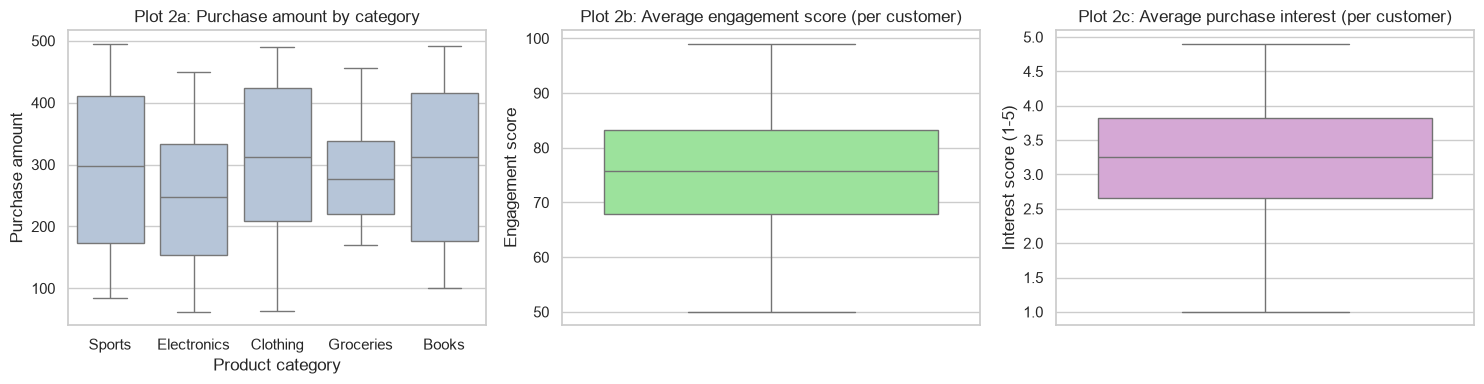

purchase_amount          outliers by 1.5*IQR rule: 0
avg_engagement           outliers by 1.5*IQR rule: 0
avg_purchase_interest    outliers by 1.5*IQR rule: 0


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=merged_check, x="product_category", y="purchase_amount", color="lightsteelblue", ax=ax[0])
ax[0].set_title("Plot 2a: Purchase amount by category"); ax[0].set_xlabel("Product category"); ax[0].set_ylabel("Purchase amount")
sns.boxplot(y=cust_profile["avg_engagement"], color="lightgreen", ax=ax[1])
ax[1].set_title("Plot 2b: Average engagement score (per customer)"); ax[1].set_ylabel("Engagement score")
sns.boxplot(y=cust_profile["avg_purchase_interest"], color="plum", ax=ax[2])
ax[2].set_title("Plot 2c: Average purchase interest (per customer)"); ax[2].set_ylabel("Interest score (1-5)")
plt.tight_layout(); plt.show()

# Count outliers with the usual 1.5 x IQR rule
for col, df in [("purchase_amount", merged_check), ("avg_engagement", cust_profile), ("avg_purchase_interest", cust_profile)]:
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:24s} outliers by 1.5*IQR rule: {n_out}")

**Interpretation.** No point falls outside the 1.5×IQR whiskers for purchase amount, engagement or purchase interest
(all counts are 0), so there are no outliers to remove and every row is kept. Median purchase amount is between about
247 (Electronics) and 312 (Books/Clothing), but the boxes overlap heavily, so **amount alone will not tell us the category**.

### Plot 3 – Correlation heatmap

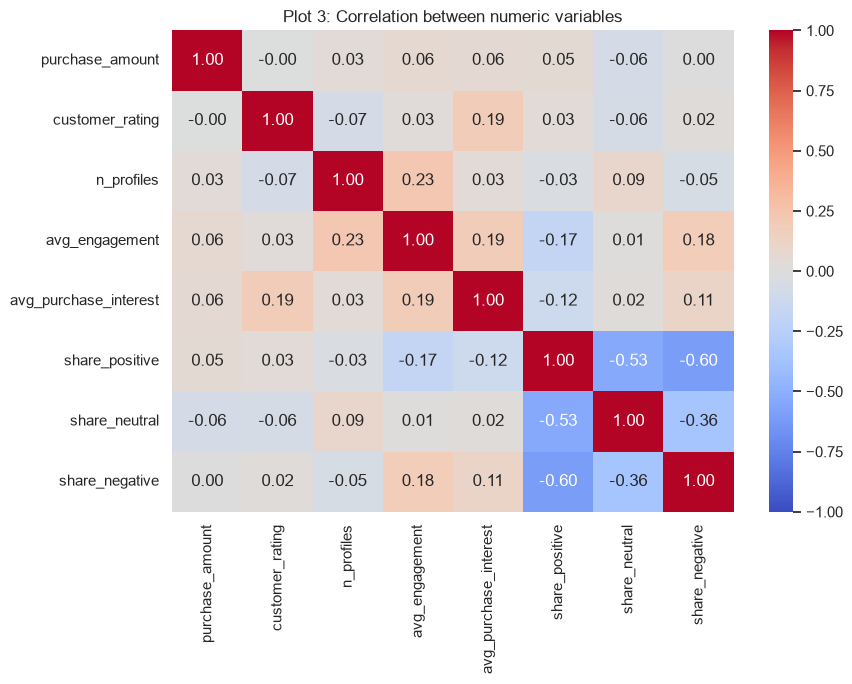

In [12]:
corr_cols = ["purchase_amount", "customer_rating", "n_profiles", "avg_engagement", "avg_purchase_interest",
             "share_positive", "share_neutral", "share_negative"]
plt.figure(figsize=(9, 7))
sns.heatmap(merged_check[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Plot 3: Correlation between numeric variables")
plt.tight_layout(); plt.show()

**Interpretation.** The strongest correlations (−0.60, −0.53, −0.36) are among the three sentiment shares, which is
expected because they add up to 1. Every other pair has |r| ≤ 0.23, so purchase values and social-media scores are
only weakly related. For modelling this means the features carry mostly **independent but weak information**, and we should
not expect a high accuracy. (The target is a category, so it is not in this numeric heatmap; its link to the features is tested by the models.)

### Plot 4 – Do social-media signals differ between product categories?

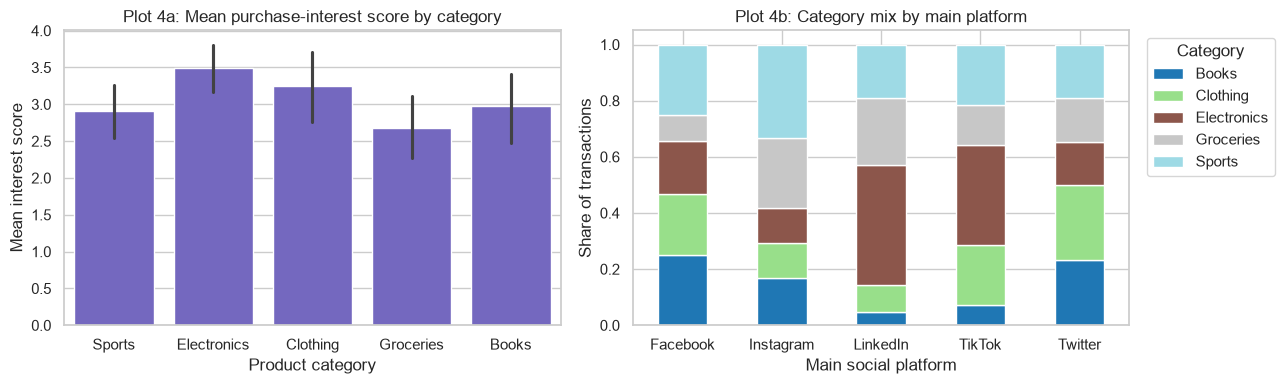

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=merged_check, x="product_category", y="avg_purchase_interest", order=order, color="slateblue", ax=ax[0])
ax[0].set_title("Plot 4a: Mean purchase-interest score by category"); ax[0].set_xlabel("Product category"); ax[0].set_ylabel("Mean interest score")
pd.crosstab(merged_check["main_platform"], merged_check["product_category"], normalize="index").plot(
    kind="bar", stacked=True, ax=ax[1], colormap="tab20")
ax[1].set_title("Plot 4b: Category mix by main platform"); ax[1].set_xlabel("Main social platform"); ax[1].set_ylabel("Share of transactions")
ax[1].legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Interpretation.** Mean purchase interest ranges only from about 2.7 (Groceries) to 3.5 (Electronics) on a 1–5 scale,
with a spread of about 1 point inside each category, so the difference is modest. Every platform has a mix of all five
categories, so there is no obvious "platform X buys category Y" rule. This matches the heatmap: the signal in this
dataset is weak, so we judge the models against the baseline rather than expecting high scores.

## 6. Feature engineering

Features come from **both** datasets. Each transaction row gets:

| Group | Features | Source |
|---|---|---|
| Social profile (per customer) | `n_profiles`, `avg_engagement`, `avg_purchase_interest`, `share_positive/neutral/negative`, `main_platform` | profiles |
| Purchase history (**only earlier transactions** of that customer) | `n_prior_txns`, `total_prior_spend`, `avg_prior_amount`, `avg_prior_rating`, `days_since_last_txn` (recency), `prior_top_category` | transactions |

**Avoiding target leakage.** The target is the `product_category` of the current transaction. We do **not** use the
current transaction's own `purchase_amount`, `customer_rating` or date as features, because they only exist once the
purchase has happened. History features are built only from transactions that happened **before** the current one.
First-time buyers have no history (`n_prior_txns = 0`); their history values are missing and are imputed in the pipeline.

**Encoding / scaling.** One-hot encoding for the two categorical columns and median imputation for missing numbers are
done **inside the model pipeline**, so they are fitted on training data only. Scaling is used for Logistic Regression
(which needs it) but not for Random Forest (which does not).

In [14]:
data = pm.build_transaction_dataset(trans, profiles)
print("Engineered dataset:", data.shape, "|", data["customer_id"].nunique(), "customers")
print("Features used by the model:", pm.FEATURE_COLS)
data.head()

Engineered dataset: (117, 19) | 61 customers
Features used by the model: ['n_profiles', 'avg_engagement', 'avg_purchase_interest', 'share_positive', 'share_neutral', 'share_negative', 'n_prior_txns', 'total_prior_spend', 'avg_prior_amount', 'avg_prior_rating', 'days_since_last_txn', 'main_platform', 'prior_top_category']


,customer_id,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,n_profiles,avg_engagement,avg_purchase_interest,share_positive,share_neutral,share_negative,main_platform,n_prior_txns,total_prior_spend,avg_prior_amount,avg_prior_rating,days_since_last_txn,prior_top_category
0,151,1001,408,2024-01-01,Sports,2.3,3,71.666667,2.166667,0.000000,0.666667,0.333333,Twitter,0,0.0,NaN,NaN,NaN,none
1,192,1002,332,2024-01-02,Electronics,4.2,1,60.000000,4.300000,1.000000,0.000000,0.000000,Instagram,0,0.0,NaN,NaN,NaN,none
2,114,1003,442,2024-01-03,Electronics,2.1,1,87.000000,4.800000,0.000000,0.000000,1.000000,Facebook,0,0.0,NaN,NaN,NaN,none
3,160,1005,64,2024-01-05,Clothing,1.3,3,72.666667,2.500000,0.333333,0.666667,0.000000,Instagram,0,0.0,NaN,NaN,NaN,none
4,120,1006,395,2024-01-06,Groceries,1.1,3,77.000000,2.666667,1.000000,0.000000,0.000000,Instagram,0,0.0,NaN,NaN,NaN,none


In [15]:
# Save the merged dataset with engineered features (handoff file)
out_cols = ["customer_id", "transaction_id", "purchase_date", "purchase_amount", "customer_rating"] \
           + pm.FEATURE_COLS + [pm.TARGET]
data[out_cols].to_csv(pm.MERGED_PATH, index=False)
print("Saved", pm.MERGED_PATH, data[out_cols].shape)
print("Columns that are NOT model inputs (reference only): purchase_date, purchase_amount, customer_rating, transaction_id")

Saved D:\ALU_Trials\dataPreProcessing\data\merged_dataset.csv (117, 19)
Columns that are NOT model inputs (reference only): purchase_date, purchase_amount, customer_rating, transaction_id


## 7. Train the models

* **Target:** `product_category` (5 classes: Books, Clothing, Electronics, Groceries, Sports) – a multi-class classification problem.
* **Split:** the same customer appears in several rows, so a random split would put the same person in both
  train and test and inflate the scores. We use **StratifiedGroupKFold grouped by `customer_id`**: classes stay balanced
  (stratified) and a customer is never in both sets. The first fold (≈20 %) is the test set.
* **Models:** Logistic Regression (scaled) and Random Forest, plus a **majority-class baseline** for comparison.
* Both models use strong regularisation (small `C`, shallow trees) because the dataset is tiny.

In [16]:
X = data[pm.FEATURE_COLS]
y = data[pm.TARGET]
groups = data["customer_id"]
CLASSES = sorted(y.unique())

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Customers in both train and test (must be 0):", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))
print("\nTrain class share:\n", y_train.value_counts(normalize=True).round(2).to_string())
print("\nTest class share:\n", y_test.value_counts(normalize=True).round(2).to_string())

Train rows: 93 | Test rows: 24
Customers in both train and test (must be 0): 0

Train class share:
 product_category
Sports         0.24
Electronics    0.23
Clothing       0.19
Groceries      0.17
Books          0.17

Test class share:
 product_category
Electronics    0.25
Sports         0.25
Books          0.17
Groceries      0.17
Clothing       0.17


In [17]:
def make_preprocessor(scale):
    # numbers: fill missing with median (+ optional scaling); text categories: one-hot
    steps = [SimpleImputer(strategy="median")] + ([StandardScaler()] if scale else [])
    return ColumnTransformer([
        ("num", make_pipeline(*steps), pm.NUMERIC_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), pm.CATEGORICAL_COLS),
    ])

def make_models():
    return {
        "Baseline (majority class)": Pipeline([("prep", make_preprocessor(False)),
                                               ("model", DummyClassifier(strategy="prior"))]),
        "Logistic Regression": Pipeline([("prep", make_preprocessor(True)),
                                         ("model", LogisticRegression(C=0.1, max_iter=2000, random_state=SEED))]),
        "Random Forest": Pipeline([("prep", make_preprocessor(False)),
                                   ("model", RandomForestClassifier(n_estimators=300, max_depth=4,
                                                                    min_samples_leaf=3, random_state=SEED))]),
    }

def proba_all_classes(model, X_):
    # predicted probabilities for ALL 5 classes (a fold might miss one class); tiny floor avoids log(0)
    p = np.full((len(X_), len(CLASSES)), 1e-3)
    raw = model.predict_proba(X_)
    for i, c in enumerate(model.classes_):
        p[:, CLASSES.index(c)] = raw[:, i]
    return p / p.sum(axis=1, keepdims=True)

def evaluate(model, X_, y_):
    pred = model.predict(X_)
    return {"accuracy": accuracy_score(y_, pred),
            "f1_macro": f1_score(y_, pred, average="macro"),
            "f1_weighted": f1_score(y_, pred, average="weighted"),
            "log_loss": log_loss(y_, proba_all_classes(model, X_), labels=CLASSES)}

models = make_models()
for name, m in models.items():
    m.fit(X_train, y_train)          # preprocessing is fitted on TRAIN data only
print("All models trained.")

All models trained.


## 8. Evaluate and compare

In [18]:
test_results = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in models.items()}).T.round(3)
print("Test-set results (single grouped split):")
test_results

Test-set results (single grouped split):


,accuracy,f1_macro,f1_weighted,log_loss
Baseline (majority class),0.250,0.080,0.100,1.593
Logistic Regression,0.333,0.332,0.337,1.677
Random Forest,0.250,0.213,0.239,1.660


A single test set of ~25 rows is very noisy, so we also run **5-fold grouped cross-validation** on all rows. This is a
more reliable comparison.

In [19]:
cv_rows = {}
for name in make_models():
    scores = []
    for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y, groups):
        m = make_models()[name].fit(X.iloc[tr], y.iloc[tr])
        scores.append(evaluate(m, X.iloc[te], y.iloc[te]))
    s = pd.DataFrame(scores)
    cv_rows[name] = {f"{c} (mean)": s[c].mean() for c in ["accuracy", "f1_macro", "log_loss"]}
    cv_rows[name].update({"accuracy (std)": s["accuracy"].std(), "f1_macro (std)": s["f1_macro"].std()})
cv_results = pd.DataFrame(cv_rows).T.round(3)
print("5-fold grouped cross-validation:")
cv_results

5-fold grouped cross-validation:


,accuracy (mean),f1_macro (mean),log_loss (mean),accuracy (std),f1_macro (std)
Baseline (majority class),0.222,0.073,1.602,0.016,0.004
Logistic Regression,0.281,0.247,1.687,0.059,0.084
Random Forest,0.256,0.198,1.626,0.047,0.065


In [20]:
# Choose the best REAL model (not the baseline) by cross-validated macro F1
real = cv_results.drop(index="Baseline (majority class)")
best_name = real["f1_macro (mean)"].idxmax()
base = cv_results.loc["Baseline (majority class)"]
print(f"Best model by CV macro F1: {best_name}")
print(f"  CV accuracy {real.loc[best_name,'accuracy (mean)']:.3f} vs baseline {base['accuracy (mean)']:.3f}")
print(f"  CV macro F1 {real.loc[best_name,'f1_macro (mean)']:.3f} vs baseline {base['f1_macro (mean)']:.3f}")
print(f"  CV log loss {real.loc[best_name,'log_loss (mean)']:.3f} vs baseline {base['log_loss (mean)']:.3f}  (lower is better)")
print(f"  Random guessing across 5 classes would give accuracy 0.200 and log loss {np.log(5):.3f}")

Best model by CV macro F1: Logistic Regression
  CV accuracy 0.281 vs baseline 0.222
  CV macro F1 0.247 vs baseline 0.073
  CV log loss 1.687 vs baseline 1.602  (lower is better)
  Random guessing across 5 classes would give accuracy 0.200 and log loss 1.609


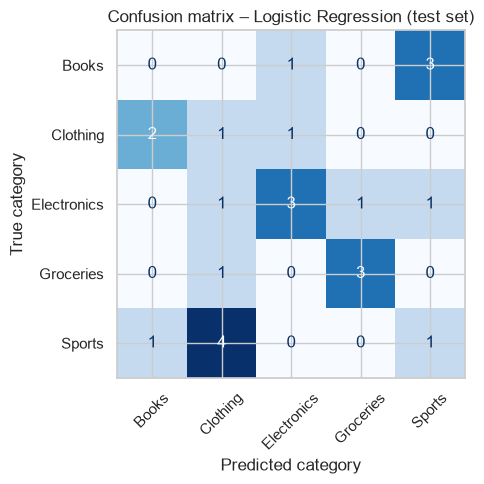

              precision    recall  f1-score   support

       Books       0.00      0.00      0.00         4
    Clothing       0.14      0.25      0.18         4
 Electronics       0.60      0.50      0.55         6
   Groceries       0.75      0.75      0.75         4
      Sports       0.20      0.17      0.18         6

    accuracy                           0.33        24
   macro avg       0.34      0.33      0.33        24
weighted avg       0.35      0.33      0.34        24



In [21]:
# Confusion matrix + per-class report for the best model on the test set
best_model = models[best_name]
pred_test = best_model.predict(X_test)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test, labels=CLASSES), display_labels=CLASSES).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title(f"Confusion matrix – {best_name} (test set)")
ax.set_xlabel("Predicted category"); ax.set_ylabel("True category")
plt.tight_layout(); plt.show()
print(classification_report(y_test, pred_test, zero_division=0))

### Comparison and what the models get wrong

* Both real models score only slightly above the majority-class baseline on accuracy (CV: 0.281 and 0.256 vs 0.222;
  the fold-to-fold standard deviation is 0.05–0.06). Macro-F1 looks higher than the baseline mainly because the baseline
  always predicts one class. Their **log loss is worse than the baseline's** (1.687 and 1.626 vs 1.602), i.e. the predicted
  probabilities are not better than just using class frequencies. So we **cannot claim that the models truly beat chance**,
  and we cannot separate Logistic Regression from Random Forest with confidence.
* On the 24-row test split the confusion matrix shows many mistakes between categories: Groceries and Electronics are
  mostly right, Books is never predicted correctly. With only 4–6 test rows per class these per-class results are very noisy.
* **Why:** the EDA already showed that social-media scores, purchase amounts and past purchases have almost no
  relationship to the category bought, and there are only 117 rows from 61 customers. This looks like a limit of the data, not a coding bug.
* We still select the model with the best cross-validated macro-F1 (shown above) because the assignment needs a working model
  for the pipeline, but we report honestly that its predictive power is limited.

## 9. Save the final model

The chosen pipeline (imputer + scaler/encoder + classifier, all in one object) is **re-fitted on all 117 rows** so the
deployed model uses all available data, then saved with the per-customer feature table used for prediction.
The metrics above come from models trained on the training split only.

In [22]:
final_pipeline = make_models()[best_name].fit(X, y)
customer_features = pm.build_customer_features(trans, profiles)      # one row per customer (all history)

bundle = {
    "pipeline": final_pipeline,            # preprocessing + model together
    "feature_cols": pm.FEATURE_COLS,
    "customer_features": customer_features,
    "classes": list(final_pipeline.classes_),
    "model_name": best_name,
}
os.makedirs(os.path.dirname(pm.MODEL_PATH), exist_ok=True)
with open(pm.MODEL_PATH, "wb") as f:
    pickle.dump(bundle, f)
print("Saved", pm.MODEL_PATH, "| model:", best_name, "| customers available:", len(customer_features))

Saved D:\ALU_Trials\dataPreProcessing\models\product_model.pkl | model: Logistic Regression | customers available: 61


## 10. Test `predict_product(customer_id)` and create demo users

In [23]:
import importlib; importlib.reload(pm)
# accepted ID formats: 'A178', 'a178', '178', 178
sample = customer_features.index[0]
for cid in [f"A{sample}", str(sample), int(sample), "A999999", "banana"]:
    print(f"predict_product({cid!r:12}) ->", pm.predict_product(cid))

predict_product('A100'      ) -> Sports
predict_product('100'       ) -> Sports
predict_product(100         ) -> Sports
predict_product('A999999'   ) -> None
predict_product('banana'    ) -> None


### Demo users
Real customer IDs from the merged dataset, one per team member, for Member 2's app. We pick customers that have both
profile data and at least one transaction. Names follow the team table; **Member 2 / Member 3 can swap the
mapping if needed**. The fourth group member is not part of the team, so only three rows are created.

In [24]:
rng = np.random.RandomState(SEED)
demo_ids = sorted(rng.choice(customer_features.index.values, size=3, replace=False))
demo_users = pd.DataFrame({"name": ["Amazing", "Kate", "Gilbert"], "customer_id": [f"A{i}" for i in demo_ids]})
demo_users.to_csv(os.path.join(ROOT, "data", "demo_users.csv"), index=False)

demo_users["predicted_product"] = [pm.predict_product(c) for c in demo_users["customer_id"]]
demo_users

,name,customer_id,predicted_product
0,Amazing,A100,Sports
1,Kate,A105,Groceries
2,Gilbert,A180,Clothing


## Summary
* Datasets merged on a cleaned `customer_id` (inner join), validated, and saved to `data/merged_dataset.csv`.
* 4 labelled EDA figures with interpretation (distribution, boxplots, correlation heatmap, group comparison).
* Two models plus a baseline compared with grouped cross-validation using accuracy, F1 and log loss.
* Final pipeline saved to `models/product_model.pkl`; `predict_product` works for known IDs and returns `None` for unknown IDs.
* **Main limitation:** the data has very little predictive signal for the product category and is small (117 rows, 61 customers), so
  predictions should be treated as a demonstration of the pipeline, not as reliable recommendations.